# 07. 기본 튜닝

## 1. 실험 목적

Scratch, Feature Extraction, Full Fine-tuning의 Learning Rate와 Weight Decay를 개별 변경하여 일반화 성능을 비교한다. 각 기준선의 나머지 조건을 유지하고 Validation Macro F1을 중심으로 Loss와 학습 곡선을 함께 고려한다. Test는 사용하지 않는다.

## 2. 공통 실험 준비

기존 결과는 재사용하며 불완전한 결과는 덮어쓰지 않는다.

In [1]:
import sys
import io
from contextlib import redirect_stdout
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import resnet18, ResNet18_Weights

# 프로젝트 루트 설정
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 공통 모듈
from src.preprocessing import (
    set_seed,
    load_data,
    get_dataloaders,
    SEED,
    IMAGE_SIZE,
    BATCH_SIZE,
    NUM_CLASSES
)

from src.training import (
    fit,
    save_training_results
)

from src.evaluation import (
    load_best_model,
    evaluate_model,
    analyze_class_performance,
    save_evaluation_results,
    save_predictions
)

# 공통 실험 설정
EPOCHS = 30
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 결과 저장 경로
OUTPUT_DIR = PROJECT_ROOT / "outputs"
RESULT_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = PROJECT_ROOT / "figures"

for directory in [OUTPUT_DIR, RESULT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


print("Device:", device)


Device: cuda


In [2]:
def run_experiment(experiment_name, learning_rate, weight_decay, strategy, backbone_lr=None):

    set_seed(SEED)
    train_loader, val_loader, _ = get_dataloaders()
    freeze_bn = strategy == "feature_extraction"
    if not freeze_bn:
        next(iter(train_loader))
    if strategy != "scratch":
        set_seed(SEED)
    model = resnet18(weights=None if strategy == "scratch" else WEIGHTS)
    if freeze_bn:
        for param in model.parameters():
            param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if strategy == "full_fine_tuning":
        params = [
            {"params": [p for name, p in model.named_parameters() if not name.startswith("fc.")], "lr": backbone_lr},
            {"params": model.fc.parameters(), "lr": learning_rate}
        ]
    else:
        params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = optim.Adam(params, lr=learning_rate, weight_decay=weight_decay)

    checkpoint_path = OUTPUT_DIR / f"{experiment_name}_best.pth"

    # 기존 실험 결과 덮어쓰기 방지
    if checkpoint_path.exists() or any(
        RESULT_DIR.glob(f"{experiment_name}_*.csv")
    ):
        raise FileExistsError(f"이미 존재하는 실험: {experiment_name}")

    # 실험 설정 기록
    experiment_config = {
        "experiment_name": experiment_name,
        "model_name": "ResNet18",
        "training_strategy": strategy,
        "pretrained_weights": "None" if strategy == "scratch" else WEIGHTS.name,
        "trainable_layers": "fc" if freeze_bn else "all",
        "freeze_backbone_bn": freeze_bn,
        "optimizer": "Adam",
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "loss_function": "CrossEntropyLoss",
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "seed": SEED,
        "image_size": IMAGE_SIZE,
        "num_classes": NUM_CLASSES,
        "scheduler": "None",
        "augmentation": "None",
        "checkpoint_metric": "val_f1"
    }

    if strategy == "full_fine_tuning":
        experiment_config.update(backbone_lr=backbone_lr, fc_lr=learning_rate)
    if freeze_bn:
        set_seed(SEED)

    with redirect_stdout(io.StringIO()):

        history_df, total_time = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            epochs=EPOCHS,
            checkpoint_path=checkpoint_path,
            freeze_backbone_bn=freeze_bn
        )

        summary_df = save_training_results(
            history_df,
            total_time,
            experiment_config,
            model,
            device,
            RESULT_DIR
        )

        model, checkpoint = load_best_model(
            model, checkpoint_path, device
        )

        evaluation = evaluate_model(
            model, val_loader, criterion, device
        )

        class_analysis = analyze_class_performance(
            evaluation["y_true"],
            evaluation["y_pred"]
        )

        save_evaluation_results(
            evaluation,
            class_analysis,
            experiment_name,
            checkpoint["epoch"],
            RESULT_DIR
        )

        save_predictions(
            evaluation,
            val_loader.dataset.df,
            val_loader,
            experiment_name,
            RESULT_DIR
        )

    return summary_df


def run_or_load(config, strategy):
    name = config["experiment_name"]
    files = [OUTPUT_DIR / f"{name}_best.pth"] + [
        RESULT_DIR / f"{name}_{suffix}.csv" for suffix in
        ("history", "summary", "evaluation", "class_report", "confusion_matrix", "confusion_pairs", "predictions")
    ]
    if all(f.exists() for f in files):
        print(f"[REUSE] {name}")
        return pd.read_csv(files[2])
    if any(f.exists() for f in files):
        raise FileExistsError(f"불완전한 기존 결과: {name}")
    print(f"[START] {name}", flush=True)
    result = run_experiment(**config, strategy=strategy)
    print(f"[DONE] Val F1: {result.iloc[0]['best_val_f1']:.4f}")
    return result


In [3]:
def compare_results(BASELINE_NAME, experiments, prefix, labels):
    # 기준선 및 튜닝 결과 로드
    experiment_names = [
        BASELINE_NAME,
        *experiments["experiment_name"].tolist()
    ]

    comparison_df = pd.concat([
        pd.read_csv(RESULT_DIR / f"{name}_summary.csv")
        for name in experiment_names
    ], ignore_index=True)

    if "fc_lr" in comparison_df:
        comparison_df["learning_rate"] = comparison_df["learning_rate"].fillna(comparison_df["fc_lr"]) if "learning_rate" in comparison_df else comparison_df["fc_lr"]

    # 성능 격차 및 기준선 대비 변화량
    comparison_df["f1_gap"] = (
        comparison_df["best_train_f1"]
        - comparison_df["best_val_f1"]
    )

    comparison_df["f1_change"] = (
        comparison_df["best_val_f1"]
        - comparison_df.loc[0, "best_val_f1"]
    )

    # 주요 비교 항목
    columns = [
        "experiment_name",
        "learning_rate",
        "weight_decay",
        "best_epoch",
        "best_train_f1",
        "best_val_f1",
        "best_val_loss",
        "f1_gap",
        "f1_change",
        "total_training_time_sec"
    ]
    if "backbone_lr" in comparison_df:
        columns.insert(2, "backbone_lr")
    comparison_df = comparison_df[columns]

    comparison_df.to_csv(
        RESULT_DIR / f"{prefix}_tuning_comparison.csv",
        index=False
    )

    display(comparison_df.round(4))
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    metrics = {
        "train_loss": "Train Loss",
        "val_loss": "Validation Loss",
        "train_f1": "Train Macro F1",
        "val_f1": "Validation Macro F1"
    }

    for name, label in zip(experiment_names, labels):

        history = pd.read_csv(
            RESULT_DIR / f"{name}_history.csv"
        )

        for ax, (metric, title) in zip(
            axes.flat, metrics.items()
        ):
            ax.plot(
                history["epoch"],
                history[metric],
                label=label,
                linestyle="--" if name == BASELINE_NAME else "-",
                color="black" if name == BASELINE_NAME else None
            )

            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(alpha=0.3)

            if metric.endswith("f1"):
                ax.set_ylim(0, 1.05)

    axes[0, 0].legend()

    fig.suptitle(f"{prefix} - Learning Curves")
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"{prefix}_tuning_learning_curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    return comparison_df

## 3. Scratch 기본 튜닝

[REUSE] scratch_tune_lr5e-4
[REUSE] scratch_tune_lr1e-4
[REUSE] scratch_tune_wd1e-4
[REUSE] scratch_tune_wd1e-3


,experiment_name,learning_rate,weight_decay,best_epoch,best_train_f1,best_val_f1,best_val_loss,f1_gap,f1_change,total_training_time_sec
0,scratch_baseline,0.0010,0.0000,29,1.0000,0.5837,1.9176,0.4163,0.0000,99.8984
1,scratch_tune_lr5e-4,0.0005,0.0000,23,1.0000,0.4695,1.9941,0.5305,-0.1142,97.7277
2,scratch_tune_lr1e-4,0.0001,0.0000,10,1.0000,0.4450,1.7649,0.5550,-0.1387,99.2272
3,scratch_tune_wd1e-4,0.0010,0.0001,30,0.9906,0.5412,2.0262,0.4494,-0.0425,100.6475
4,scratch_tune_wd1e-3,0.0010,0.0010,23,0.9377,0.4601,2.1967,0.4775,-0.1236,101.0154


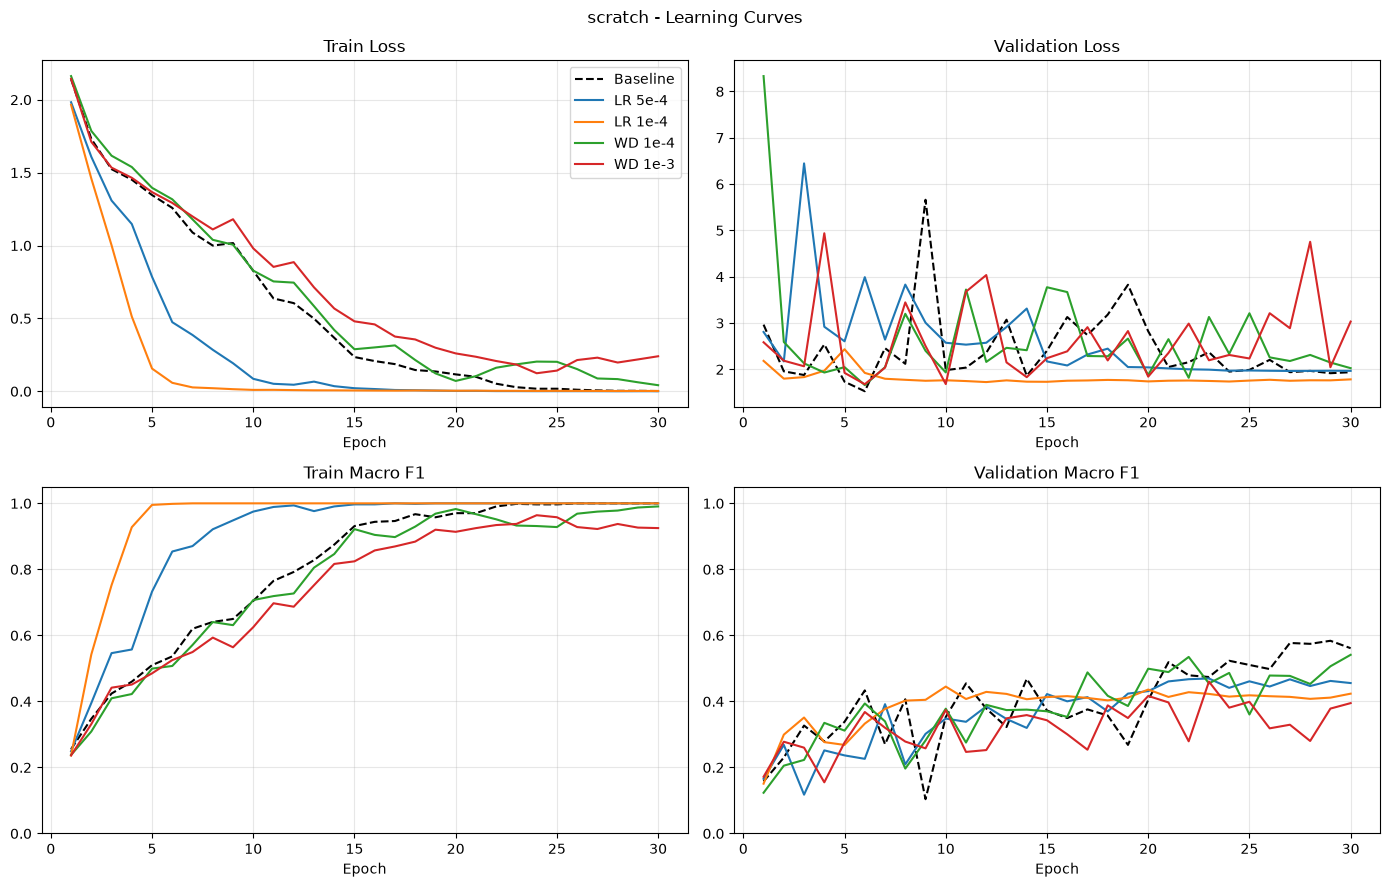

In [4]:
experiments = pd.DataFrame([
    {
        "experiment_name": "scratch_tune_lr5e-4",
        "learning_rate": 5e-4,
        "weight_decay": 0
    },
    {
        "experiment_name": "scratch_tune_lr1e-4",
        "learning_rate": 1e-4,
        "weight_decay": 0
    },
    {
        "experiment_name": "scratch_tune_wd1e-4",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4
    },
    {
        "experiment_name": "scratch_tune_wd1e-3",
        "learning_rate": 1e-3,
        "weight_decay": 1e-3
    }
])

for config in experiments.to_dict("records"):
    run_or_load(config, "scratch")

scratch_comparison = compare_results("scratch_baseline", experiments, "scratch", ['Baseline', 'LR 5e-4', 'LR 1e-4', 'WD 1e-4', 'WD 1e-3'])

### 결과 해석

- Learning Rate 감소 시 Train Loss가 빠르게 감소하고
  Train Macro F1이 1.0에 도달했으나, Validation 성능은
  기준선보다 낮은 수준에서 정체되었다.

- Weight Decay 적용 시 학습 데이터에 대한 적합이 일부
  제한되었으나, Validation 성능 개선으로 이어지지 않았다.

- 튜닝 후보 중 Weight Decay 1e-4가 가장 높은
  Macro F1(0.5412)을 기록했으나 기준선(0.5837)보다 낮았다.

- 단일 Seed 및 제한된 Validation 데이터에서의 결과이므로
  하이퍼파라미터의 일반적인 효과로 확대 해석하지 않는다.

**모델 선정**

현재 실험 범위에서는 Scratch 기준선 설정
(Learning Rate 1e-3, Weight Decay 0)을 유지한다.

개별 변경에서 성능 개선이 확인되지 않아 조합 실험은
생략하고, 이후 오류 분석 기반 개선 가능성을 검토한다.

## 4. Feature Extraction 기본 튜닝

[REUSE] feature_extraction_tune_lr5e-4
[REUSE] feature_extraction_tune_lr3e-3
[REUSE] feature_extraction_tune_wd1e-4


,experiment_name,learning_rate,weight_decay,best_epoch,best_train_f1,best_val_f1,best_val_loss,f1_gap,f1_change,total_training_time_sec
0,feature_extraction_baseline,0.0010,0.0000,17,0.9814,0.8765,0.4087,0.1049,0.0000,73.0206
1,feature_extraction_tune_lr5e-4,0.0005,0.0000,23,0.9703,0.8704,0.4377,0.0999,-0.0061,107.2898
2,feature_extraction_tune_lr3e-3,0.0030,0.0000,27,1.0000,0.8807,0.4699,0.1193,0.0042,105.8683
3,feature_extraction_tune_wd1e-4,0.0010,0.0001,17,0.9814,0.8765,0.4087,0.1049,0.0000,105.5088


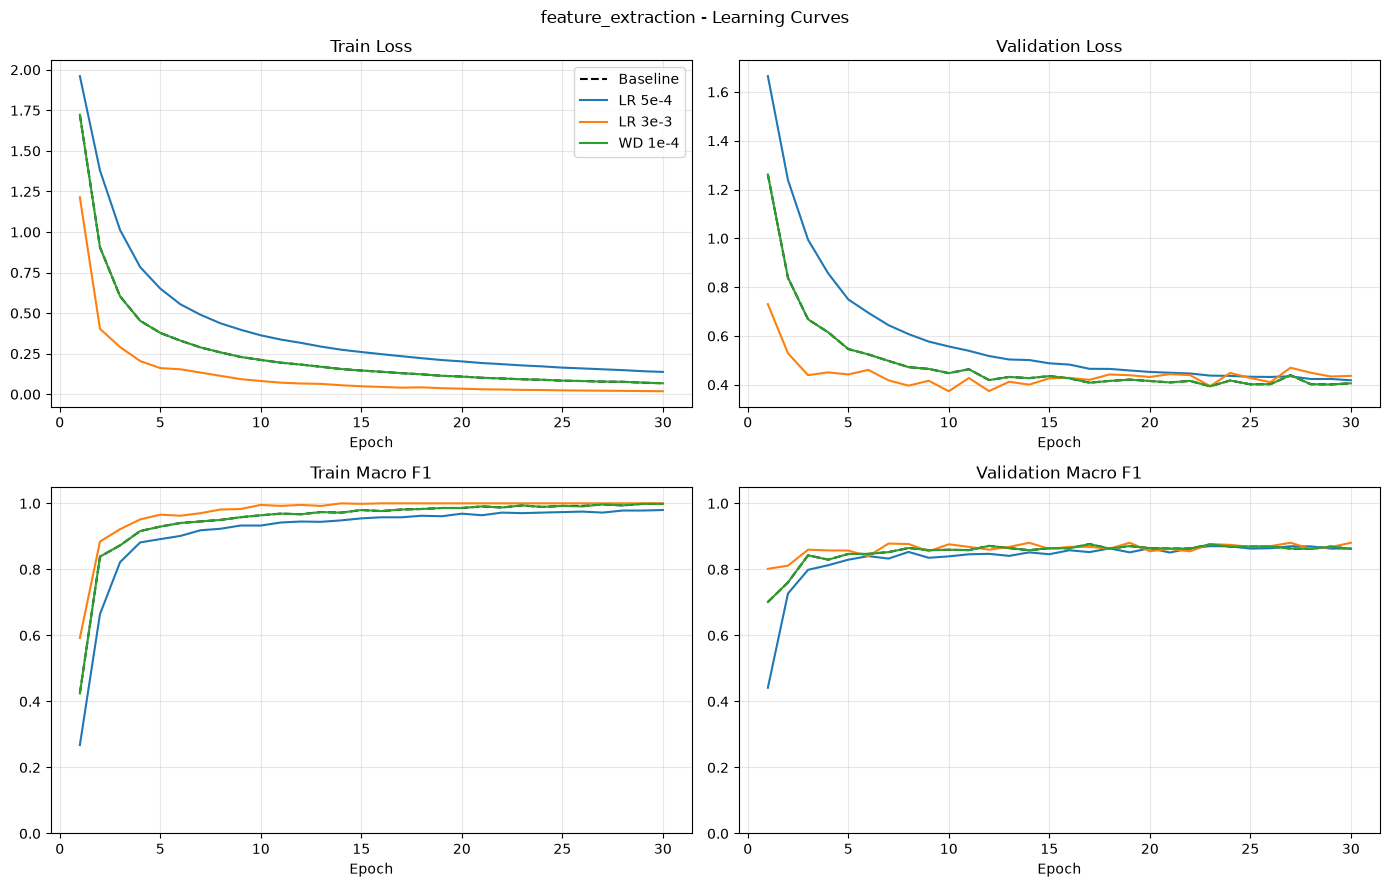

In [5]:
experiments = pd.DataFrame([
    {
        "experiment_name": "feature_extraction_tune_lr5e-4",
        "learning_rate": 5e-4,
        "weight_decay": 0
    },
    {
        "experiment_name": "feature_extraction_tune_lr3e-3",
        "learning_rate": 3e-3,
        "weight_decay": 0
    },
    {
        "experiment_name": "feature_extraction_tune_wd1e-4",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4
    }
])

for config in experiments.to_dict("records"):
    run_or_load(config, "feature_extraction")

feature_extraction_comparison = compare_results("feature_extraction_baseline", experiments, "feature_extraction", ['Baseline', 'LR 5e-4', 'LR 3e-3', 'WD 1e-4'])

### 결과 해석

- Learning Rate 감소(5e-4)는 수렴 속도를 늦추었으며,
  Validation 성능 개선으로 이어지지 않았다.

- Learning Rate 증가(3e-3)는 수렴 속도를 높이고
  Validation Macro F1을 0.42%p 개선하였으나,
  Validation Loss와 Train–Validation F1 격차가 증가하였다.

- Weight Decay(1e-4)는 기준선과 거의 동일한 학습 곡선 및
  평가 결과를 보여 뚜렷한 개선 효과가 확인되지 않았다.

**모델 선정**

단일 Seed와 제한된 Validation 데이터에서 나타난
소폭의 F1 향상을 과도하게 해석하지 않고,
Validation Loss 및 과적합 양상을 종합적으로 고려하여
기존 기준선 설정(LR 1e-3, Weight Decay 0)을 유지한다.

조합 실험은 생략한다.

## 5. Full Fine-tuning 기본 튜닝

기준선에서 관찰된 빠른 학습 데이터 적합과 과적합 양상을
완화하기 위해 Backbone Learning Rate와 Weight Decay를
개별적으로 변경한다.

FC Learning Rate는 1e-3으로 고정하며,
사전학습 Backbone을 포함한 전체 파라미터를 학습한다.

[REUSE] fine_tuning_tune_backbone_lr5e-5
[REUSE] fine_tuning_tune_backbone_lr1e-5
[REUSE] fine_tuning_tune_wd1e-4
[REUSE] fine_tuning_tune_wd1e-3


,experiment_name,learning_rate,backbone_lr,weight_decay,best_epoch,best_train_f1,best_val_f1,best_val_loss,f1_gap,f1_change,total_training_time_sec
0,fine_tuning_baseline,0.001,0.0001,0.0000,26,1.0,0.8913,0.4671,0.1087,0.0000,97.8118
1,fine_tuning_tune_backbone_lr5e-5,0.001,0.0000,0.0000,24,1.0,0.8786,0.4750,0.1214,-0.0128,126.1595
2,fine_tuning_tune_backbone_lr1e-5,0.001,0.0000,0.0000,20,1.0,0.8719,0.4582,0.1281,-0.0195,126.9141
3,fine_tuning_tune_wd1e-4,0.001,0.0001,0.0001,26,1.0,0.8913,0.4659,0.1087,0.0000,126.9882
4,fine_tuning_tune_wd1e-3,0.001,0.0001,0.0010,14,1.0,0.8853,0.4359,0.1147,-0.0060,127.7624


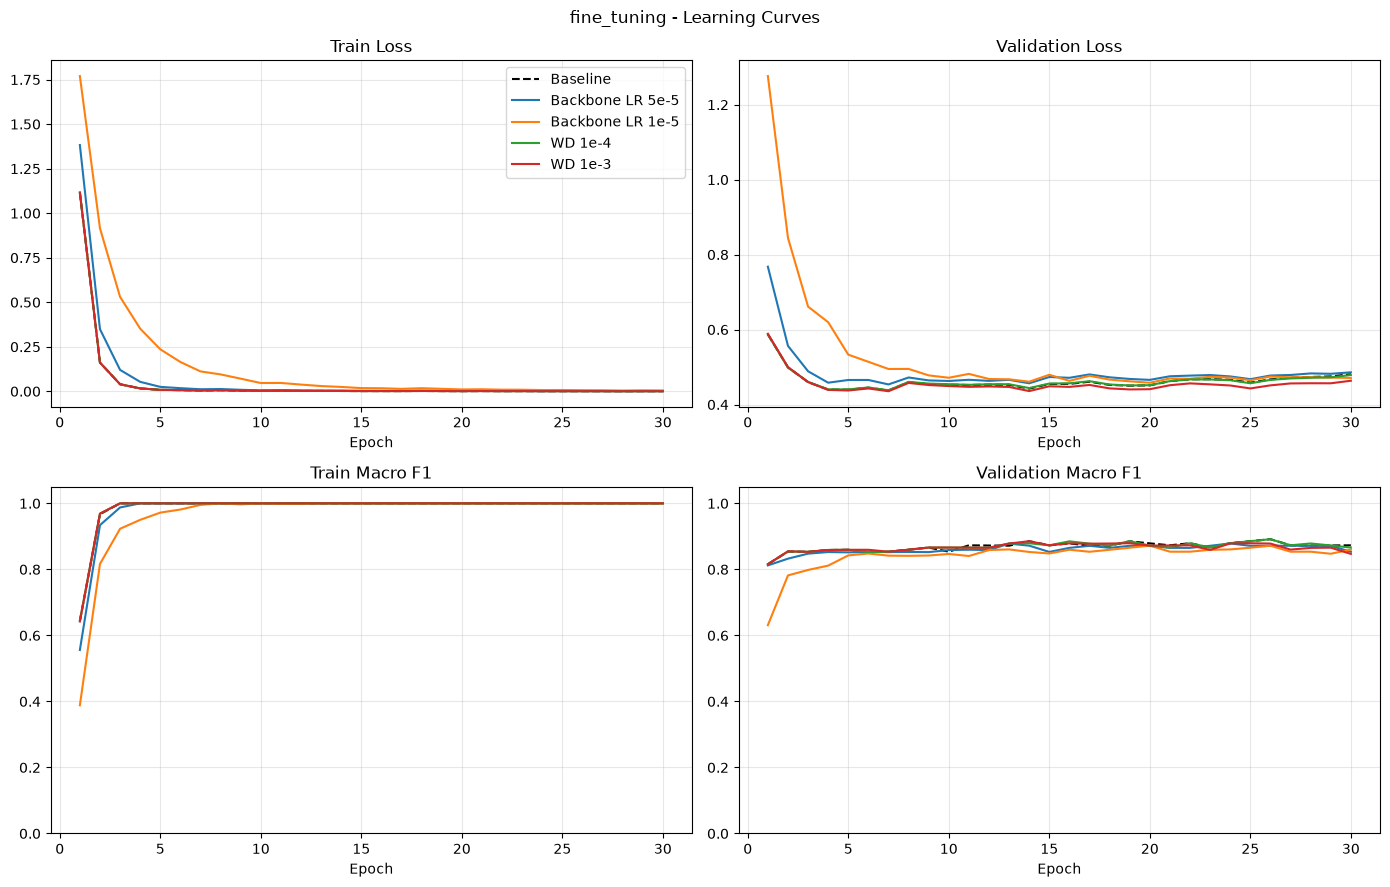

In [6]:
ft_experiments = pd.DataFrame([
    {
        "experiment_name": "fine_tuning_tune_backbone_lr5e-5",
        "backbone_lr": 5e-5,
        "learning_rate": 1e-3,
        "weight_decay": 0
    },
    {
        "experiment_name": "fine_tuning_tune_backbone_lr1e-5",
        "backbone_lr": 1e-5,
        "learning_rate": 1e-3,
        "weight_decay": 0
    },
    {
        "experiment_name": "fine_tuning_tune_wd1e-4",
        "backbone_lr": 1e-4,
        "learning_rate": 1e-3,
        "weight_decay": 1e-4
    },
    {
        "experiment_name": "fine_tuning_tune_wd1e-3",
        "backbone_lr": 1e-4,
        "learning_rate": 1e-3,
        "weight_decay": 1e-3
    }
])

for config in ft_experiments.to_dict("records"):
    run_or_load(config, "full_fine_tuning")

ft_comparison = compare_results(
    "fine_tuning_baseline",
    ft_experiments,
    "fine_tuning",
    [
        "Baseline",
        "Backbone LR 5e-5",
        "Backbone LR 1e-5",
        "WD 1e-4",
        "WD 1e-3"
    ]
)

### 결과 해석

**Learning Rate 변경**

- Backbone Learning Rate를 감소시킬수록 초기 학습 수렴 속도가 느려졌으나, 모든 실험에서 최종적으로 Train Macro F1이 1.0에 도달하였다.
- Validation Macro F1은 기준선 대비 각각 1.28%p, 1.95%p 감소하였으며, Train과 Validation의 성능 격차도 증가하였다.
- 따라서 Backbone Learning Rate 감소는 과적합 완화 및 분류 성능 개선으로 이어지지 않았다.

**Weight Decay 변경**

- Weight Decay 1e-4 적용 시 기준선과 동일한 Validation Macro F1을 기록하였으며, 학습 곡선에서도 뚜렷한 차이가 나타나지 않았다.
- Weight Decay 1e-3 적용 시 Validation Loss가 0.4671에서 0.4359로 감소하였으나, Validation Macro F1은 0.60%p 감소하였다.
- Weight Decay 적용에 따른 Loss 개선 가능성은 확인하였으나, 핵심 평가 지표인 Macro F1의 개선은 확인하지 못하였다.

**학습 효율**

- 모든 튜닝 실험에서 기준선 대비 학습 시간이 증가하였다.
- 실험 환경 및 GPU 상태의 영향을 배제할 수 없으므로, 학습 시간 증가를 하이퍼파라미터 변경의 직접적인 영향으로 해석하지 않는다.

**결론**

Full Fine-tuning 기본 튜닝에서는 기준선 대비 명확한 성능 개선을 확인하지 못하였다. 단일 Seed와 제한된 Validation 데이터 규모를 고려하여 기존 기준선 설정을 유지한다.

개별 하이퍼파라미터 변경에서 뚜렷한 분류 성능 개선이 확인되지 않았으므로 추가 조합 실험은 수행하지 않는다. 이후 오류 분석을 통해 데이터 및 모델의 특성을 파악하고, 이를 기반으로 추가 개선 실험을 설계한다.

## 6. 종합 비교 및 결론

Scratch, Feature Extraction, Full Fine-tuning의 기본 튜닝
결과를 종합적으로 비교한다.

Validation Macro F1을 중심으로 Validation Loss,
Train-Validation 성능 격차 및 학습 효율을 함께 고려하여
각 학습 전략의 설정을 선정한다.

In [7]:
strategy_names = {
    "scratch": "Scratch",
    "feature_extraction": "Feature Extraction",
    "fine_tuning": "Full Fine-tuning"
}

summary_rows = []

for strategy, label in strategy_names.items():
    comparison = pd.read_csv(
        RESULT_DIR / f"{strategy}_tuning_comparison.csv"
    )

    baseline_name = f"{strategy}_baseline"

    baseline = comparison.loc[
        comparison["experiment_name"] == baseline_name
    ].iloc[0]

    tuned = comparison.loc[
        comparison["experiment_name"] != baseline_name
    ]

    best_tuned = tuned.loc[tuned["best_val_f1"].idxmax()]

    summary_rows.append({
        "strategy": label,
        "n_experiments": len(tuned),
        "baseline_f1": baseline["best_val_f1"],
        "best_tuned_f1": best_tuned["best_val_f1"],
        "f1_change": (
            best_tuned["best_val_f1"] - baseline["best_val_f1"]
        ),
        "baseline_val_loss": baseline["best_val_loss"],
        "best_tuned_val_loss": best_tuned["best_val_loss"],
        "best_tuned_experiment": best_tuned["experiment_name"],
        "selected_experiment": baseline_name,
        "selected_val_f1": baseline["best_val_f1"]
    })

tuning_summary = pd.DataFrame(summary_rows)

tuning_summary.to_csv(
    RESULT_DIR / "basic_tuning_summary.csv",
    index=False
)

display(tuning_summary.round(4))

,strategy,n_experiments,baseline_f1,best_tuned_f1,f1_change,baseline_val_loss,best_tuned_val_loss,best_tuned_experiment,selected_experiment,selected_val_f1
0,Scratch,4,0.5837,0.5412,-0.0425,1.9176,2.0262,scratch_tune_wd1e-4,scratch_baseline,0.5837
1,Feature Extraction,3,0.8765,0.8807,0.0042,0.4087,0.4699,feature_extraction_tune_lr3e-3,feature_extraction_baseline,0.8765
2,Full Fine-tuning,4,0.8913,0.8913,0.0000,0.4671,0.4659,fine_tuning_tune_wd1e-4,fine_tuning_baseline,0.8913


### 종합 결과 해석

**Learning Rate 변경 효과**

- Scratch에서는 Learning Rate 감소에 따른 Validation 성능 개선이 확인되지 않았다.
- Feature Extraction에서는 Learning Rate 3e-3 적용 시 Validation Macro F1이 소폭 증가하였으나, Validation Loss와 Train-Validation 성능 격차도 증가하였다.
- Full Fine-tuning에서는 Backbone Learning Rate 감소에 따라 초기 수렴 속도가 느려졌으며, 최종 Validation 성능도 감소하였다.

**Weight Decay 변경 효과**

- Scratch에서는 Weight Decay 적용으로 학습 데이터에 대한 적합이 일부 제한되었으나, Validation 성능 개선으로 이어지지 않았다.
- Feature Extraction과 Full Fine-tuning에서는 Weight Decay 1e-4 적용 시 기준선과 거의 동일한 결과가 나타났다.
- Full Fine-tuning에서 Weight Decay 1e-3 적용 시 Validation Loss가 감소하였으나, 핵심 평가 지표인 Macro F1은 감소하였다.

**학습 전략별 비교**

- 기본 튜닝 이후에도 Scratch, Feature Extraction, Full Fine-tuning 순으로 Validation 성능이 높게 나타났다.
- 본 실험 범위에서는 하이퍼파라미터 조정보다 학습 전략 간 성능 차이가 상대적으로 크게 나타났다.
- 제한된 학습 데이터에서 사전학습 가중치를 활용하는 Transfer Learning의 유용성을 확인하였다.

**최종 설정 선정**

총 11회의 기본 튜닝 실험을 수행하였으나, 기준선을 대체할 만큼 명확한 성능 개선은 확인하지 못하였다.

Feature Extraction의 일부 실험에서 Macro F1이 소폭 증가하였으나, Validation Loss 및 성능 격차 증가와 제한된 Validation 데이터 규모를 종합적으로 고려하여 세 학습 전략 모두 기존 기준선 설정을 유지한다.

단일 Random Seed와 제한된 하이퍼파라미터 탐색 범위에서 수행된 실험이므로, 본 결과를 각 학습 전략의 최적 하이퍼파라미터를 탐색한 결과로 해석하지 않는다.

이후에는 선정된 모델의 클래스별 성능 및 오분류 사례를 분석하고, 관찰된 오류 특성에 근거하여 추가 개선 실험을 설계한다.